# Time, depth mesh visualization

## Region and path

In [1]:
# grid paths
import xarray as xr

# Save to
path_output='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_sensitivity/Data_Vertical_Integrate/'

# grids: tmesh, area and e3t
# paths

MASK_FILE = "/ocean/jqiu/Grid/mesh_mask202108.nc"
AREA_FILE = "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_biol_T.nc"


ds_grid=xr.open_dataset(MASK_FILE)
tmask=ds_grid['tmask'] # String flag_meanings "land, water"; String flag_values "0, 1", (t, z, y, x)
e3t=ds_grid['e3t_1d'] # "Grid Spacing on T-grid in w Direction", (t, z)
depth=ds_grid['gdept_1d'] # "Depth of T-grid Points", String units "m", (t, z)

ds_area=xr.open_dataset(AREA_FILE)
area=ds_area['area'] # 


# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"

EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

# List_month={'Mar','Jun','Sep','Dec'}
List_month={'Mar'}

## Sensitivity Visualization

### Puget Sound

Processing: HRDPS2.5
Processing: HRDPS2.5+CaSR_wind
Processing: CaSR+HRDPS2.5_wind


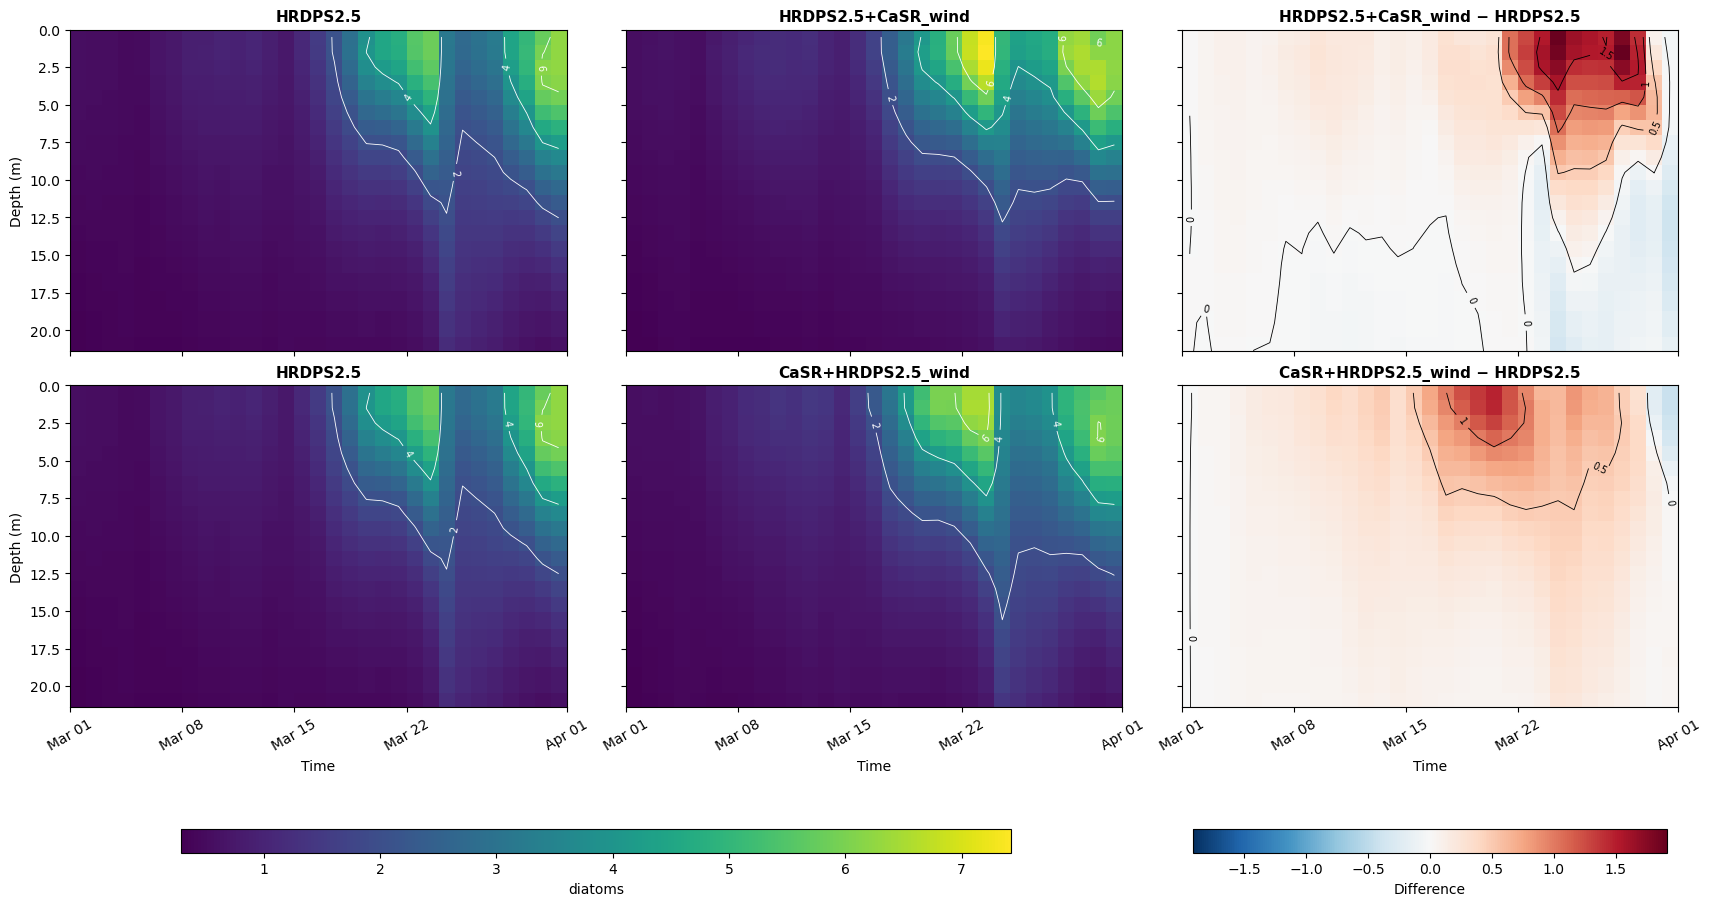

In [5]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm



MONTH = "Mar"

REFERENCE = "HRDPS2.5"

EXPERIMENTS = [
    "HRDPS2.5+CaSR_wind",
    "CaSR+HRDPS2.5_wind"
]

VARIABLE = "diatoms"
DATA_TYPE = "Biological"

REGION = "Puget Sound"
N_LEVELS = 20

CMAP = "viridis"
VMIN = None
VMAX = None

DIFF_CMAP = "RdBu_r"
DIFF_MAX = None

CONTOUR_LEVELS = np.arange(0, 8, 2)
DIFF_CONTOUR_LEVELS = np.arange(-4, 4, 0.5)


# weights

y0, y1, x0, x1 = REGIONS[REGION]

region_area = area.isel(
    y=slice(y0, y1),
    x=slice(x0, x1)
).squeeze(drop=True)

mask = tmask.isel(
    t=0,
    z=slice(0, N_LEVELS),
    y=slice(y0, y1),
    x=slice(x0, x1)
).rename({"z": "deptht"})

weights = region_area.where(mask == 1, 0)


# calculate the mean

results = {}

for exp in [REFERENCE] + EXPERIMENTS:

    file_path = (
        EXPERIMENTS_head[exp][MONTH]
        + EXPERIMENTS_tail[DATA_TYPE]
    )

    print(f"Processing: {exp}")

    with xr.open_dataset(file_path) as ds:

        da = ds[VARIABLE].isel(
            deptht=slice(0, N_LEVELS),
            y=slice(y0, y1),
            x=slice(x0, x1)
        )

        # Match grid coordinates
        w = weights.assign_coords(
            deptht=da.deptht,
            y=da.y,
            x=da.x
        )

        # Area-weighted mean for each depth
        results[exp] = da.weighted(w).mean(
            dim=("y", "x")
        ).load()


# difference

aligned = {}

for exp in EXPERIMENTS:

    ref, exp_da = xr.align(
        results[REFERENCE],
        results[exp],
        join="inner"
    )

    diff = exp_da - ref

    aligned[exp] = {
        "ref": ref,
        "exp": exp_da,
        "diff": diff
    }


# limits

all_absolute = []

for exp in EXPERIMENTS:
    all_absolute.extend([
        aligned[exp]["ref"],
        aligned[exp]["exp"]
    ])

vmin = (
    VMIN if VMIN is not None
    else min(float(da.min()) for da in all_absolute)
)

vmax = (
    VMAX if VMAX is not None
    else max(float(da.max()) for da in all_absolute)
)

diff_max = (
    DIFF_MAX if DIFF_MAX is not None
    else max(
        float(abs(aligned[exp]["diff"]).max())
        for exp in EXPERIMENTS
    )
)

diff_norm = TwoSlopeNorm(
    vmin=-diff_max,
    vcenter=0,
    vmax=diff_max
)


# visualize

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

absolute_meshes = []
diff_meshes = []

for row, exp in enumerate(EXPERIMENTS):

    data_list = [
        aligned[exp]["ref"],
        aligned[exp]["exp"],
        aligned[exp]["diff"]
    ]

    titles = [
        REFERENCE,
        exp,
        f"{exp} − {REFERENCE}"
    ]

    for col, (da, title) in enumerate(
        zip(data_list, titles)
    ):

        ax = axes[row, col]

        time = pd.to_datetime(
            da.time_counter.values
        )

        depth = da.deptht.values

        values = da.transpose(
            "deptht", "time_counter"
        ).values

        if col < 2:
            cmap = CMAP
            norm = None
            levels = CONTOUR_LEVELS
            contour_color = "white"
        else:
            cmap = DIFF_CMAP
            norm = diff_norm
            levels = DIFF_CONTOUR_LEVELS
            contour_color = "black"

        mesh = ax.pcolormesh(
            time,
            depth,
            values,
            shading="auto",
            cmap=cmap,
            vmin=vmin if col < 2 else None,
            vmax=vmax if col < 2 else None,
            norm=norm,
            rasterized=True
        )

        if col < 2:
            absolute_meshes.append(mesh)
        else:
            diff_meshes.append(mesh)

        # Contours
        if levels is not None:

            cs = ax.contour(
                time,
                depth,
                values,
                levels=levels,
                colors=contour_color,
                linewidths=0.6
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=7,
                fmt="%g"
            )

        ax.set_title(
            title,
            fontsize=11,
            fontweight="bold"
        )

        ax.xaxis.set_major_locator(
            mdates.AutoDateLocator(
                minticks=3,
                maxticks=7
            )
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(
            axis="x",
            rotation=30
        )

        ax.set_ylim(depth.max(), 0)

    axes[row, 0].set_ylabel("Depth (m)")


# Time labels only on bottom row
for ax in axes[-1, :]:
    ax.set_xlabel("Time")


# colorbars


# One colorbar for reference and experiments
cbar1 = fig.colorbar(
    absolute_meshes[0],
    ax=axes[:, :2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=35
)

cbar1.set_label(VARIABLE)

# One colorbar for differences
cbar2 = fig.colorbar(
    diff_meshes[0],
    ax=axes[:, 2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=20
)

cbar2.set_label("Difference")



plt.show()



## CaSR, HRDPS 10 and HRDPS 1

Processing: HRDPS2.5
Processing: HRDPS1
Processing: CaSR
Processing: HRDPS10


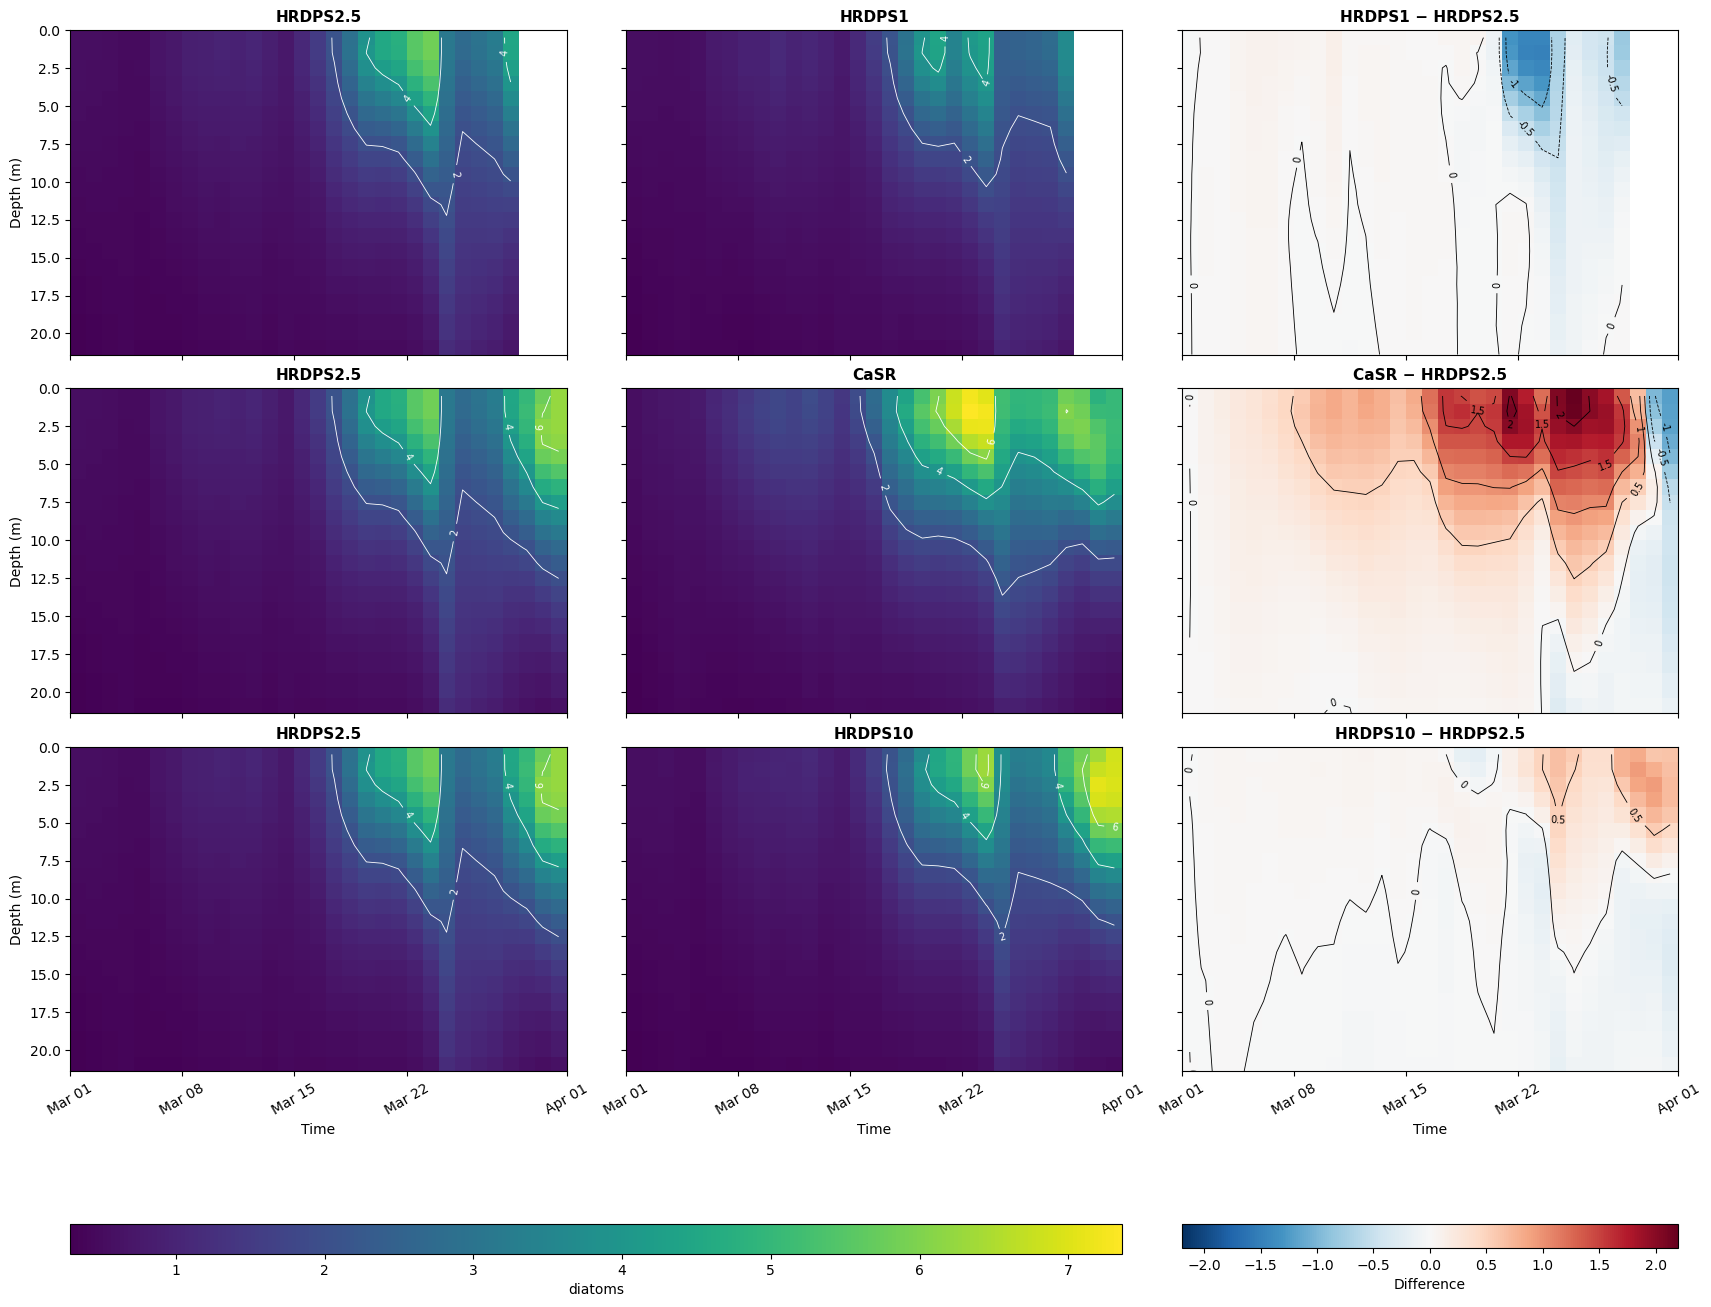

In [ ]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm


# ============================================================
# Settings
# ============================================================

MONTH = "Mar"

REFERENCE = "HRDPS2.5"

EXPERIMENTS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10"
]

VARIABLE = "diatoms"
DATA_TYPE = "Biological"

REGION = "Puget Sound"
N_LEVELS = 20

CMAP = "viridis"
VMIN = None
VMAX = None

DIFF_CMAP = "RdBu_r"
DIFF_MAX = None

CONTOUR_LEVELS = np.arange(0, 8, 2)
DIFF_CONTOUR_LEVELS = np.arange(-4, 4, 0.5)


# ============================================================
# Area weights
# ============================================================

y0, y1, x0, x1 = REGIONS[REGION]

region_area = area.isel(
    y=slice(y0, y1),
    x=slice(x0, x1)
).squeeze(drop=True)

mask = tmask.isel(
    t=0,
    z=slice(0, N_LEVELS),
    y=slice(y0, y1),
    x=slice(x0, x1)
).rename({"z": "deptht"})

weights = region_area.where(mask == 1, 0)

# Calculate the mean


results = {}

for exp in [REFERENCE] + EXPERIMENTS:

    file_path = (
        EXPERIMENTS_head[exp][MONTH]
        + EXPERIMENTS_tail[DATA_TYPE]
    )

    print(f"Processing: {exp}")

    with xr.open_dataset(file_path) as ds:

        da = ds[VARIABLE].isel(
            deptht=slice(0, N_LEVELS),
            y=slice(y0, y1),
            x=slice(x0, x1)
        )

        # Match grid coordinates
        w = weights.assign_coords(
            deptht=da.deptht,
            y=da.y,
            x=da.x
        )

        # Area-weighted mean for each depth
        results[exp] = da.weighted(w).mean(
            dim=("y", "x")
        ).load()


# calculate differences


aligned = {}

for exp in EXPERIMENTS:

    ref, exp_da = xr.align(
        results[REFERENCE],
        results[exp],
        join="inner"
    )

    diff = exp_da - ref

    aligned[exp] = {
        "ref": ref,
        "exp": exp_da,
        "diff": diff
    }


# limits

all_absolute = []

for exp in EXPERIMENTS:
    all_absolute.extend([
        aligned[exp]["ref"],
        aligned[exp]["exp"]
    ])

vmin = (
    VMIN if VMIN is not None
    else min(float(da.min()) for da in all_absolute)
)

vmax = (
    VMAX if VMAX is not None
    else max(float(da.max()) for da in all_absolute)
)

diff_max = (
    DIFF_MAX if DIFF_MAX is not None
    else max(
        float(abs(aligned[exp]["diff"]).max())
        for exp in EXPERIMENTS
    )
)

diff_norm = TwoSlopeNorm(
    vmin=-diff_max,
    vcenter=0,
    vmax=diff_max
)


# visualize

fig, axes = plt.subplots(
    3, 3,
    figsize=(17, 13),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

absolute_meshes = []
diff_meshes = []

for row, exp in enumerate(EXPERIMENTS):

    data_list = [
        aligned[exp]["ref"],
        aligned[exp]["exp"],
        aligned[exp]["diff"]
    ]

    titles = [
        REFERENCE,
        exp,
        f"{exp} − {REFERENCE}"
    ]

    for col, (da, title) in enumerate(
        zip(data_list, titles)
    ):

        ax = axes[row, col]

        time = pd.to_datetime(
            da.time_counter.values
        )

        depth = da.deptht.values

        values = da.transpose(
            "deptht", "time_counter"
        ).values

        if col < 2:
            cmap = CMAP
            norm = None
            levels = CONTOUR_LEVELS
            contour_color = "white"
        else:
            cmap = DIFF_CMAP
            norm = diff_norm
            levels = DIFF_CONTOUR_LEVELS
            contour_color = "black"

        mesh = ax.pcolormesh(
            time,
            depth,
            values,
            shading="auto",
            cmap=cmap,
            vmin=vmin if col < 2 else None,
            vmax=vmax if col < 2 else None,
            norm=norm,
            rasterized=True
        )

        if col < 2:
            absolute_meshes.append(mesh)
        else:
            diff_meshes.append(mesh)

        # Contours
        if levels is not None:

            cs = ax.contour(
                time,
                depth,
                values,
                levels=levels,
                colors=contour_color,
                linewidths=0.6
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=7,
                fmt="%g"
            )

        ax.set_title(
            title,
            fontsize=11,
            fontweight="bold"
        )

        ax.xaxis.set_major_locator(
            mdates.AutoDateLocator(
                minticks=3,
                maxticks=7
            )
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(
            axis="x",
            rotation=30
        )

        ax.set_ylim(depth.max(), 0)

    axes[row, 0].set_ylabel("Depth (m)")


# Time labels only on bottom row
for ax in axes[-1, :]:
    ax.set_xlabel("Time")


# Shared colorbars


# One colorbar for reference and experiments
cbar1 = fig.colorbar(
    absolute_meshes[0],
    ax=axes[:, :2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=35
)

cbar1.set_label(VARIABLE)

# One colorbar for differences
cbar2 = fig.colorbar(
    diff_meshes[0],
    ax=axes[:, 2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=20
)

cbar2.set_label("Difference")


plt.show()


## CaSR wind vs HRDPS 10 wind

Processing: HRDPS2.5
Processing: HRDPS2.5+CaSR_wind
Processing: HRDPS10


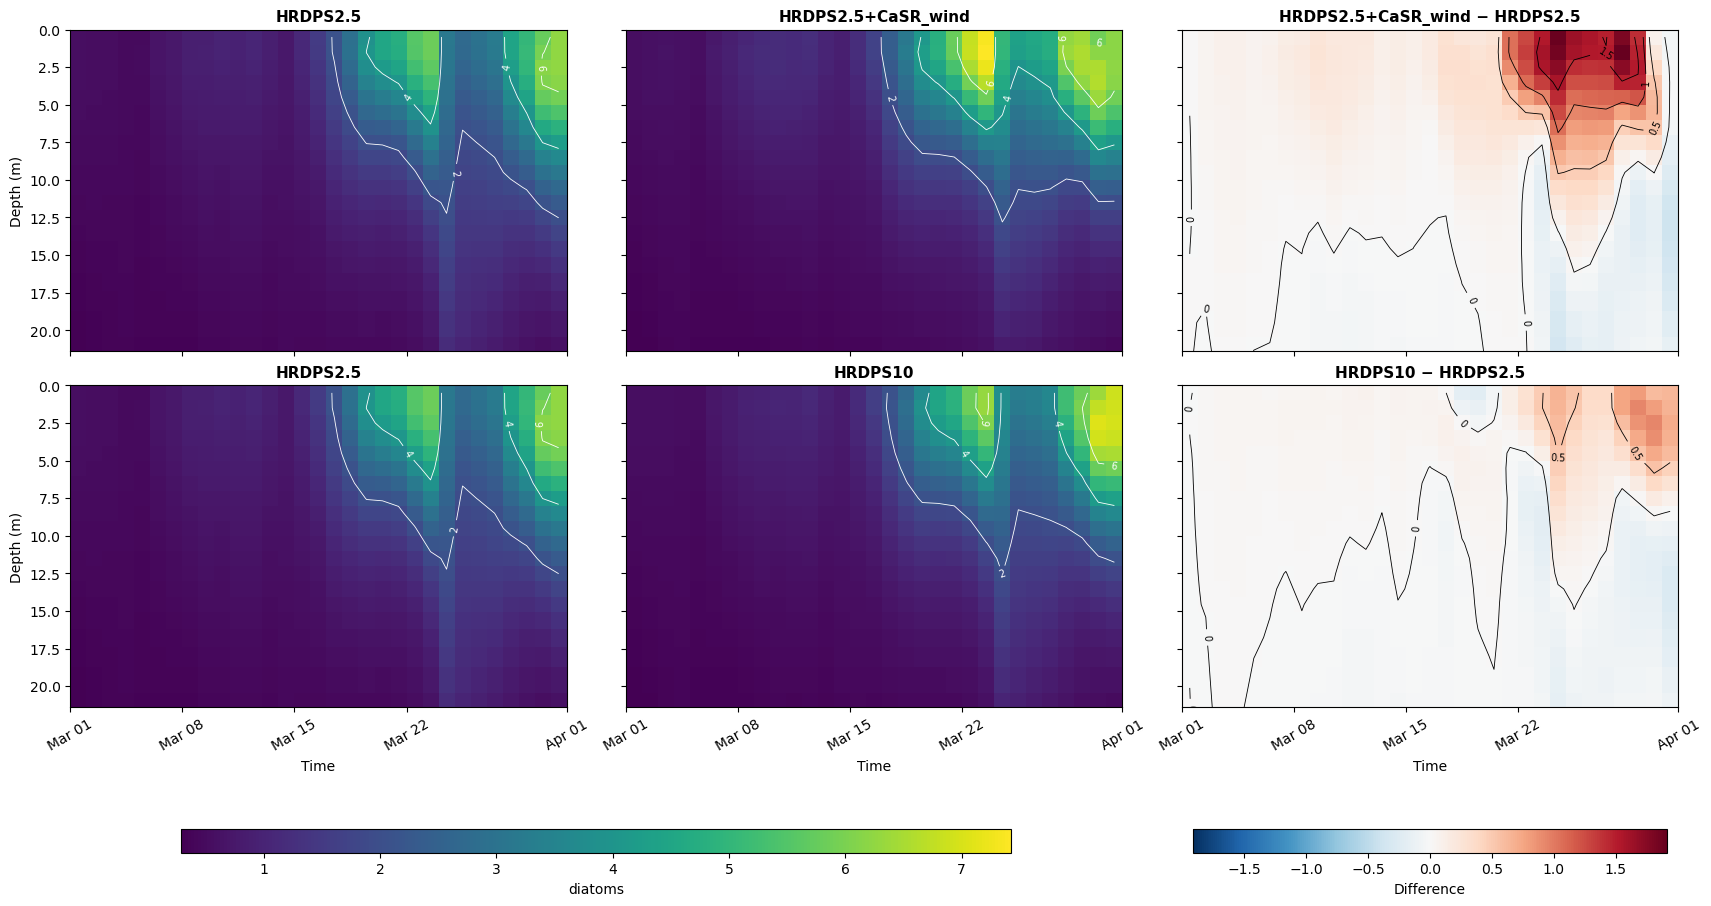

In [7]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm

MONTH = "Mar"

REFERENCE = "HRDPS2.5"

EXPERIMENTS = [
    "HRDPS2.5+CaSR_wind",
    "HRDPS10"
]

VARIABLE = "diatoms"
DATA_TYPE = "Biological"

REGION = "Puget Sound"
N_LEVELS = 20

CMAP = "viridis"
VMIN = None
VMAX = None

DIFF_CMAP = "RdBu_r"
DIFF_MAX = None

CONTOUR_LEVELS = np.arange(0, 8, 2)
DIFF_CONTOUR_LEVELS = np.arange(-4, 4, 0.5)


# weights

y0, y1, x0, x1 = REGIONS[REGION]

region_area = area.isel(
    y=slice(y0, y1),
    x=slice(x0, x1)
).squeeze(drop=True)

mask = tmask.isel(
    t=0,
    z=slice(0, N_LEVELS),
    y=slice(y0, y1),
    x=slice(x0, x1)
).rename({"z": "deptht"})

weights = region_area.where(mask == 1, 0)


# calculate the mean

results = {}

for exp in [REFERENCE] + EXPERIMENTS:

    file_path = (
        EXPERIMENTS_head[exp][MONTH]
        + EXPERIMENTS_tail[DATA_TYPE]
    )

    print(f"Processing: {exp}")

    with xr.open_dataset(file_path) as ds:

        da = ds[VARIABLE].isel(
            deptht=slice(0, N_LEVELS),
            y=slice(y0, y1),
            x=slice(x0, x1)
        )

        # Match grid coordinates
        w = weights.assign_coords(
            deptht=da.deptht,
            y=da.y,
            x=da.x
        )

        # Area-weighted mean for each depth
        results[exp] = da.weighted(w).mean(
            dim=("y", "x")
        ).load()


# difference

aligned = {}

for exp in EXPERIMENTS:

    ref, exp_da = xr.align(
        results[REFERENCE],
        results[exp],
        join="inner"
    )

    diff = exp_da - ref

    aligned[exp] = {
        "ref": ref,
        "exp": exp_da,
        "diff": diff
    }


# limits

all_absolute = []

for exp in EXPERIMENTS:
    all_absolute.extend([
        aligned[exp]["ref"],
        aligned[exp]["exp"]
    ])

vmin = (
    VMIN if VMIN is not None
    else min(float(da.min()) for da in all_absolute)
)

vmax = (
    VMAX if VMAX is not None
    else max(float(da.max()) for da in all_absolute)
)

diff_max = (
    DIFF_MAX if DIFF_MAX is not None
    else max(
        float(abs(aligned[exp]["diff"]).max())
        for exp in EXPERIMENTS
    )
)

diff_norm = TwoSlopeNorm(
    vmin=-diff_max,
    vcenter=0,
    vmax=diff_max
)


# visualize

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

absolute_meshes = []
diff_meshes = []

for row, exp in enumerate(EXPERIMENTS):

    data_list = [
        aligned[exp]["ref"],
        aligned[exp]["exp"],
        aligned[exp]["diff"]
    ]

    titles = [
        REFERENCE,
        exp,
        f"{exp} − {REFERENCE}"
    ]

    for col, (da, title) in enumerate(
        zip(data_list, titles)
    ):

        ax = axes[row, col]

        time = pd.to_datetime(
            da.time_counter.values
        )

        depth = da.deptht.values

        values = da.transpose(
            "deptht", "time_counter"
        ).values

        if col < 2:
            cmap = CMAP
            norm = None
            levels = CONTOUR_LEVELS
            contour_color = "white"
        else:
            cmap = DIFF_CMAP
            norm = diff_norm
            levels = DIFF_CONTOUR_LEVELS
            contour_color = "black"

        mesh = ax.pcolormesh(
            time,
            depth,
            values,
            shading="auto",
            cmap=cmap,
            vmin=vmin if col < 2 else None,
            vmax=vmax if col < 2 else None,
            norm=norm,
            rasterized=True
        )

        if col < 2:
            absolute_meshes.append(mesh)
        else:
            diff_meshes.append(mesh)

        # Contours
        if levels is not None:

            cs = ax.contour(
                time,
                depth,
                values,
                levels=levels,
                colors=contour_color,
                linewidths=0.6
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=7,
                fmt="%g"
            )

        ax.set_title(
            title,
            fontsize=11,
            fontweight="bold"
        )

        ax.xaxis.set_major_locator(
            mdates.AutoDateLocator(
                minticks=3,
                maxticks=7
            )
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(
            axis="x",
            rotation=30
        )

        ax.set_ylim(depth.max(), 0)

    axes[row, 0].set_ylabel("Depth (m)")


# Time labels only on bottom row
for ax in axes[-1, :]:
    ax.set_xlabel("Time")


# colorbars


# One colorbar for reference and experiments
cbar1 = fig.colorbar(
    absolute_meshes[0],
    ax=axes[:, :2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=35
)

cbar1.set_label(VARIABLE)

# One colorbar for differences
cbar2 = fig.colorbar(
    diff_meshes[0],
    ax=axes[:, 2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=20
)

cbar2.set_label("Difference")



plt.show()

## PAR + Diatom at Puget Sound

In [1]:
# grid paths
import xarray as xr


# grids: tmesh, area and e3t
# paths

MASK_FILE = "/ocean/jqiu/Grid/mesh_mask202108.nc"
AREA_FILE = "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_biol_T.nc"


ds_grid=xr.open_dataset(MASK_FILE)
tmask=ds_grid['tmask'] # String flag_meanings "land, water"; String flag_values "0, 1", (t, z, y, x)
e3t=ds_grid['e3t_1d'] # "Grid Spacing on T-grid in w Direction", (t, z)
depth=ds_grid['gdept_1d'] # "Depth of T-grid Points", String units "m", (t, z)

ds_area=xr.open_dataset(AREA_FILE)
area=ds_area['area'] # 


# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"

EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc',
    'Flux':'_sbfx_T.nc'
}

# List_month={'Mar','Jun','Sep','Dec'}
List_month={'Mar'}

Processing biological data: HRDPS2.5
Processing biological data: HRDPS1
Processing biological data: CaSR
Processing biological data: HRDPS10
Processing PAR: HRDPS2.5
Processing PAR: HRDPS1
Processing PAR: CaSR
Processing PAR: HRDPS10


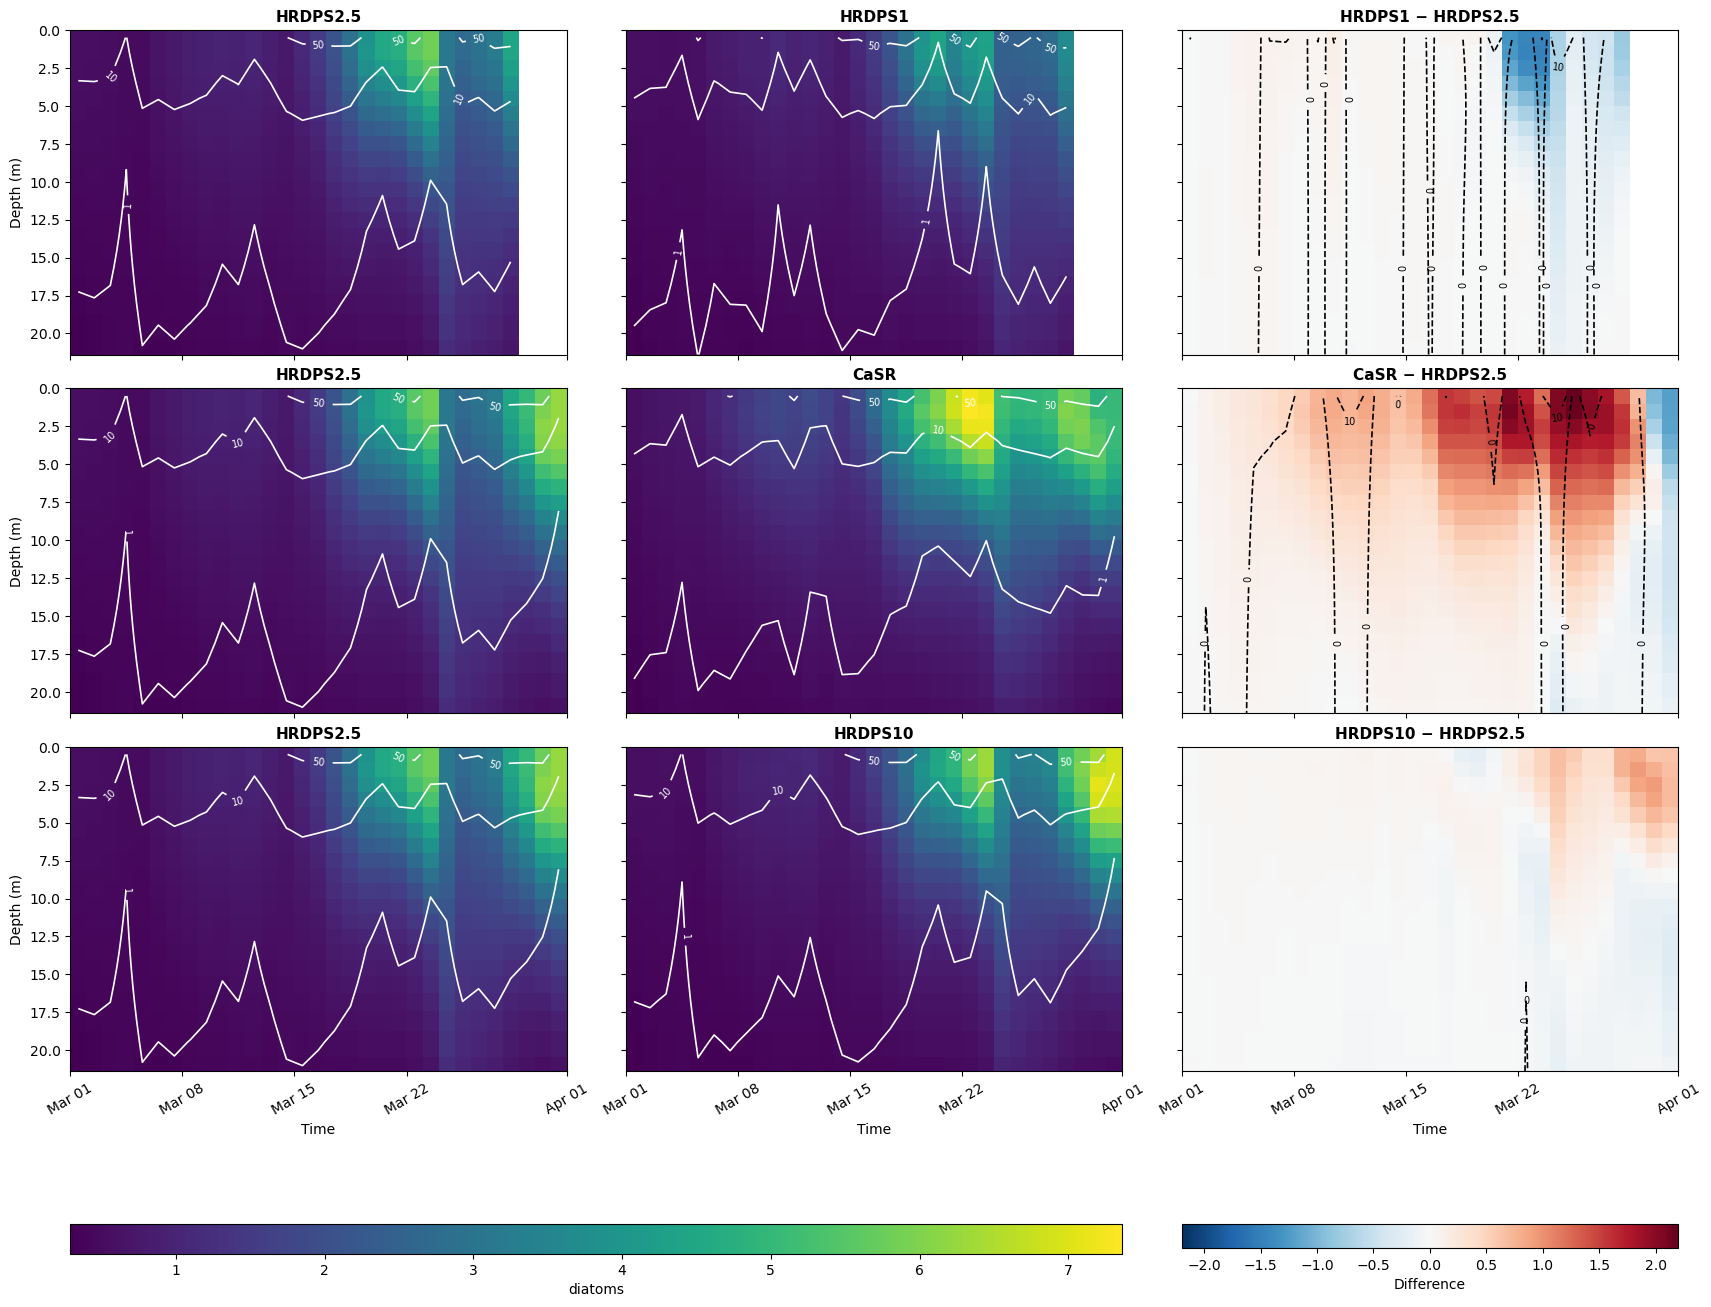

In [6]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm


# ============================================================
# Settings
# ============================================================

MONTH = "Mar"

REFERENCE = "HRDPS2.5"

EXPERIMENTS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10"
]

VARIABLE = "diatoms"
DATA_TYPE = "Biological"

REGION = "Puget Sound"
N_LEVELS = 20

CMAP = "viridis"
VMIN = None
VMAX = None

DIFF_CMAP = "RdBu_r"
DIFF_MAX = None

# PAR contours: absolute values
PAR_VARIABLE = "PAR"
PAR_CONTOUR_LEVELS = [1, 10, 50, 100]

# PAR contours: experiment minus reference
PAR_DIFF_CONTOUR_LEVELS = [
    -50,-10,0,10,50
]


# ============================================================
# Area weights
# ============================================================

y0, y1, x0, x1 = REGIONS[REGION]

region_area = area.isel(
    y=slice(y0, y1),
    x=slice(x0, x1)
).squeeze(drop=True)

mask = tmask.isel(
    t=0,
    z=slice(0, N_LEVELS),
    y=slice(y0, y1),
    x=slice(x0, x1)
).rename({"z": "deptht"})

weights = region_area.where(mask == 1, 0)


# ============================================================
# Load biological data
# ============================================================

results = {}

for exp in [REFERENCE] + EXPERIMENTS:

    file_path = (
        EXPERIMENTS_head[exp][MONTH]
        + EXPERIMENTS_tail[DATA_TYPE]
    )

    print(f"Processing biological data: {exp}")

    with xr.open_dataset(file_path) as ds:

        da = ds[VARIABLE].isel(
            deptht=slice(0, N_LEVELS),
            y=slice(y0, y1),
            x=slice(x0, x1)
        )

        w = weights.assign_coords(
            deptht=da.deptht,
            y=da.y,
            x=da.x
        )

        results[exp] = da.weighted(w).mean(
            dim=("y", "x")
        ).load()


# ============================================================
# Load PAR from chem_T
# Include reference and all experiments
# ============================================================

par_results = {}

for exp in [REFERENCE] + EXPERIMENTS:

    file_path = (
        EXPERIMENTS_head[exp][MONTH]
        + EXPERIMENTS_tail["Chemical"]
    )

    print(f"Processing PAR: {exp}")

    with xr.open_dataset(file_path) as ds:

        par = ds[PAR_VARIABLE].isel(
            deptht=slice(0, N_LEVELS),
            y=slice(y0, y1),
            x=slice(x0, x1)
        )

        w = weights.assign_coords(
            deptht=par.deptht,
            y=par.y,
            x=par.x
        )

        par_results[exp] = par.weighted(w).mean(
            dim=("y", "x")
        ).load()


# ============================================================
# Calculate biological and PAR differences
# ============================================================

aligned = {}

for exp in EXPERIMENTS:

    # Biological data
    ref = results[REFERENCE]
    exp_da = results[exp]

    ref, exp_da = xr.align(ref, exp_da, join="inner")

    diff = exp_da - ref

    # PAR data
    par_ref = par_results[REFERENCE]
    par_exp = par_results[exp]

    par_ref, par_exp = xr.align(
        par_ref, par_exp, join="inner"
    )

    par_diff = par_exp - par_ref

    aligned[exp] = {
        "ref": ref,
        "exp": exp_da,
        "diff": diff,
        "par_ref": par_ref,
        "par_exp": par_exp,
        "par_diff": par_diff
    }


# ============================================================
# Color limits
# ============================================================

all_absolute = []

for exp in EXPERIMENTS:
    all_absolute.extend([
        aligned[exp]["ref"],
        aligned[exp]["exp"]
    ])

vmin = (
    VMIN if VMIN is not None
    else min(float(da.min()) for da in all_absolute)
)

vmax = (
    VMAX if VMAX is not None
    else max(float(da.max()) for da in all_absolute)
)

diff_max = (
    DIFF_MAX if DIFF_MAX is not None
    else max(
        float(abs(aligned[exp]["diff"]).max())
        for exp in EXPERIMENTS
    )
)

if diff_max == 0:
    diff_max = 1e-12

diff_norm = TwoSlopeNorm(
    vmin=-diff_max,
    vcenter=0,
    vmax=diff_max
)


# ============================================================
# Visualization
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(17, 13),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

absolute_meshes = []
diff_meshes = []

for row, exp in enumerate(EXPERIMENTS):

    data_list = [
        aligned[exp]["ref"],
        aligned[exp]["exp"],
        aligned[exp]["diff"]
    ]

    par_list = [
        aligned[exp]["par_ref"],
        aligned[exp]["par_exp"],
        aligned[exp]["par_diff"]
    ]

    titles = [
        REFERENCE,
        exp,
        f"{exp} − {REFERENCE}"
    ]

    for col, (da, par, title) in enumerate(
        zip(data_list, par_list, titles)
    ):

        ax = axes[row, col]

        # ----------------------------------------------------
        # Biological data
        # ----------------------------------------------------

        time = pd.to_datetime(
            da.time_counter.values
        )

        depth = da.deptht.values

        values = da.transpose(
            "deptht", "time_counter"
        ).values

        if col < 2:
            cmap = CMAP
            norm = None
        else:
            cmap = DIFF_CMAP
            norm = diff_norm

        mesh = ax.pcolormesh(
            time,
            depth,
            values,
            shading="auto",
            cmap=cmap,
            vmin=vmin if col < 2 else None,
            vmax=vmax if col < 2 else None,
            norm=norm,
            rasterized=True
        )

        if col < 2:
            absolute_meshes.append(mesh)
        else:
            diff_meshes.append(mesh)

        # ----------------------------------------------------
        # PAR contours
        # ----------------------------------------------------

        par_time = pd.to_datetime(
            par.time_counter.values
        )

        par_depth = par.deptht.values

        par_values = par.transpose(
            "deptht", "time_counter"
        ).values

        if col < 2:

            # Absolute PAR contours
            par_levels = PAR_CONTOUR_LEVELS
            par_color = "white"
            par_linestyle = "solid"

        else:

            # PAR difference contours
            par_levels = PAR_DIFF_CONTOUR_LEVELS
            par_color = "black"
            par_linestyle = "dashed"

        # Only plot levels within actual data range
        finite_values = par_values[
            np.isfinite(par_values)
        ]

        if finite_values.size > 0:

            par_min = finite_values.min()
            par_max = finite_values.max()

            valid_levels = [
                level for level in par_levels
                if par_min < level < par_max
            ]

            if valid_levels:

                cs_par = ax.contour(
                    par_time,
                    par_depth,
                    par_values,
                    levels=valid_levels,
                    colors=par_color,
                    linewidths=1.2,
                    linestyles=par_linestyle
                )

                ax.clabel(
                    cs_par,
                    inline=True,
                    fontsize=7,
                    fmt="%g"
                )

        # ----------------------------------------------------
        # Axis formatting
        # ----------------------------------------------------

        ax.set_title(
            title,
            fontsize=11,
            fontweight="bold"
        )

        ax.xaxis.set_major_locator(
            mdates.AutoDateLocator(
                minticks=3,
                maxticks=7
            )
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(
            axis="x",
            rotation=30
        )

        ax.set_ylim(depth.max(), 0)

    axes[row, 0].set_ylabel("Depth (m)")


# ============================================================
# Axis labels
# ============================================================

for ax in axes[-1, :]:
    ax.set_xlabel("Time")


# ============================================================
# Shared colorbars
# ============================================================

cbar1 = fig.colorbar(
    absolute_meshes[0],
    ax=axes[:, :2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=35
)

cbar1.set_label(VARIABLE)

cbar2 = fig.colorbar(
    diff_meshes[0],
    ax=axes[:, 2].ravel().tolist(),
    orientation="horizontal",
    fraction=0.035,
    pad=0.08,
    aspect=20
)

cbar2.set_label("Difference")

plt.show()

